# PhonoLens · Notebook 3: Scoring, Indian-English norms, fairness & the app
Needs the fine-tuned model from Notebook 2 (`models/phonolens-ft` on Drive).

| Part | What it does |
|---|---|
| **1. Formant tracker fix** | Tunes our LPC tracker (bandwidth limit + median smoothing) against Praat |
| **2. Indian-English norms** | Runs fluent Indian-English speech (IndicTTS) through the system: vowel targets, durations, and per-phone GOP thresholds |
| **3. GOP + scorer** | CTC likelihood-ratio GOP features, plus a regressor trained on speechocean762's expert phone scores; ablation of whether the classical features help |
| **4. Rule A vs Rule B** | Strict flags vs Indian-English-aware flags on the unseen Hindi-L1 speakers |
| **5. Fairness check** | Flag rates across 19 Indian first languages (Svarah): does Rule B judge accents more evenly? |
| **6–8. App** | Gradio app (public link), FastAPI backup behind a Cloudflare tunnel, and a `server.py` package for running on a laptop |

**Run:** T4 GPU runtime → cell 1 (may restart once) → Run all. About 40–60 min in total.

In [ ]:
# Cell 1: install (restarts the runtime once if needed)
import os
try:
    import datasets
    need_restart = not datasets.__version__.startswith(("2.", "3."))
except ImportError:
    need_restart = True
!pip install -q "datasets>=2.19,<4" librosa soundfile praat-parselmouth g2p_en gradio fastapi uvicorn python-multipart
if need_restart:
    print("Restarting runtime so the pinned `datasets` version loads. Run the next cells after this.")
    os.kill(os.getpid(), 9)
else:
    print("Packages ready ✅")

Packages ready ✅


In [ ]:
# Cell 2: Drive, paths, local data copy
import os, json, shutil, time
from google.colab import drive
drive.mount('/content/drive')

SAVE    = "/content/drive/MyDrive/phonolens_data"
LOCAL   = "/content/data"
FT_BEST = f"{SAVE}/models/phonolens-ft"
APP_DIR = f"{SAVE}/models/phonolens-app"          # scorer, norms, thresholds, formant config
FIG, RES = f"{SAVE}/figures", f"{SAVE}/results"
for d in (FIG, RES, LOCAL, APP_DIR):
    os.makedirs(d, exist_ok=True)
assert os.path.exists(f"{FT_BEST}/config.json"), "Fine-tuned model not found: run Notebook 2 first."
for name in ["l2arctic", "speechocean", "svarah"]:
    if not os.path.exists(f"{LOCAL}/{name}"):
        t = time.time(); shutil.copytree(f"{SAVE}/{name}", f"{LOCAL}/{name}")
        print(f"copied {name} in {time.time()-t:.0f}s")
import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU (slow)")

Mounted at /content/drive
copied l2arctic in 21s
copied speechocean in 21s
copied svarah in 31s
Device: Tesla T4


In [ ]:
%%writefile /content/drive/MyDrive/phonolens_data/phonolens_core.py
"""
phonolens_core.py — shared code for the PhonoLens project.

Sections
  1. Phone set (CMU-39 written in IPA) + normalisation of any IPA / ARPAbet input
  2. Alignment (Levenshtein) + mispronunciation detection & diagnosis (MDD) metrics
  3. CTC helpers: greedy decoding, Viterbi forced alignment
  4. Classical speech processing: pre-emphasis, framing, VAD, LPC (Levinson-Durbin), formants
  5. Feedback text for common Indian-English substitutions
"""
from collections import Counter
import numpy as np

# =============================================================================
# 1. PHONE SET
# =============================================================================
# CMU ARPAbet 39-phone set (the one L2-ARCTIC and speechocean762 are labelled in),
# written in IPA so it matches the L2-ARCTIC 'ipa' / 'g2p' columns.
ARPA2IPA = {
    "AA": "ɑ", "AE": "æ", "AH": "ʌ", "AO": "ɔ", "AW": "aʊ", "AY": "aɪ", "EH": "ɛ",
    "ER": "ɝ", "EY": "eɪ", "IH": "ɪ", "IY": "i", "OW": "oʊ", "OY": "ɔɪ", "UH": "ʊ",
    "UW": "u", "B": "b", "CH": "tʃ", "D": "d", "DH": "ð", "F": "f", "G": "ɡ",
    "HH": "h", "JH": "dʒ", "K": "k", "L": "l", "M": "m", "N": "n", "NG": "ŋ",
    "P": "p", "R": "ɹ", "S": "s", "SH": "ʃ", "T": "t", "TH": "θ", "V": "v",
    "W": "w", "Y": "j", "Z": "z", "ZH": "ʒ",
}
PHONES = sorted(set(ARPA2IPA.values()))                     # 39 phones
PH2ID = {p: i + 1 for i, p in enumerate(PHONES)}              # CTC labels: 0 = blank
ID2PH = {i: p for p, i in PH2ID.items()}
VOWELS = {"ɑ", "æ", "ʌ", "ɔ", "aʊ", "aɪ", "ɛ", "ɝ", "eɪ", "ɪ", "i", "oʊ", "ɔɪ", "ʊ", "u"}
MONOPHTHONGS = VOWELS - {"aʊ", "aɪ", "eɪ", "oʊ", "ɔɪ"}

# Marks we throw away (stress, length, tones, most diacritics, syllabicity, ties).
_STRIP = set("ˈˌːˑ̩̯̃ʰʲʷ̥̬̪̺̻͡‿.|-_ ") | {"̩", "̯", "̃", "͡", "˞"}

# Symbol rewrites applied before tokenising. Order matters (longest first).
# Several of these are deliberate accent-fairness decisions: e.g. Indian-English
# monophthongs [e:] / [o:] are mapped onto the FACE / GOAT diphthongs, and a tapped
# or trilled r is mapped onto /ɹ/, so these accent features are NOT counted as errors.
_REWRITES = [
    ("ɝɹ", "ɝ"), ("ɚɹ", "ɝ"), ("ɜɹ", "ɝ"), ("əɹ", "ɝ"),
    ("əʊ", "oʊ"), ("eə", "ɛ"), ("ɪə", "ɪ"), ("ʊə", "ʊ"), ("aɪə", "aɪ"),
    ("ɚ", "ɝ"), ("ɜ", "ɝ"), ("ə", "ʌ"), ("ɐ", "ʌ"), ("ᵻ", "ɪ"), ("ɨ", "ɪ"),
    ("ʉ", "u"), ("ɯ", "u"), ("y", "i"), ("ɒ", "ɑ"), ("ɫ", "l"), ("g", "ɡ"),
    ("ɾ", "ɹ"), ("r", "ɹ"), ("ɻ", "ɹ"), ("ʀ", "ɹ"), ("ʁ", "ɹ"),
    ("ʈ", "t"), ("ɖ", "d"), ("ɳ", "n"), ("ɭ", "l"), ("ʂ", "ʃ"), ("ɕ", "ʃ"), ("ʑ", "ʒ"),
    ("x", "k"), ("q", "k"), ("ç", "h"), ("ɦ", "h"), ("β", "v"), ("ʋ", "v"), ("ɸ", "f"),
    ("c", "k"), ("ɟ", "ɡ"), ("ɲ", "n"), ("ʎ", "l"), ("ʔ", ""),
]
# Single symbols that are only valid as part of a longer phone, or need a default.
_LONE = {"e": "eɪ", "o": "oʊ", "a": "ɑ"}

_PHONES_BY_LEN = sorted(PHONES, key=len, reverse=True)


def _clean(s):
    s = "".join(ch for ch in s if ch not in _STRIP)
    for a, b in _REWRITES:
        s = s.replace(a, b)
    return s


def ipa_to_phones(s, keep_unknown=False):
    """Split an IPA string (spaces optional) into CMU-39 phones (in IPA).

    Greedy longest-match, so 'tʃ', 'aɪ', 'oʊ' stay as one phone.
    Unknown symbols are dropped (or kept as '?' if keep_unknown=True).
    """
    s = _clean(s)
    out, i = [], 0
    while i < len(s):
        for p in _PHONES_BY_LEN:
            if s.startswith(p, i):
                out.append(p)
                i += len(p)
                break
        else:
            ch = s[i]
            if ch in _LONE:
                out.append(_LONE[ch])
            elif keep_unknown:
                out.append("?")
            i += 1
    # collapse 'ɝ ɹ' that can appear after rewrites
    res = []
    for p in out:
        if p == "ɹ" and res and res[-1] == "ɝ":
            continue
        res.append(p)
    return res


def tokens_to_phones(tokens):
    """Normalise a list of model tokens (e.g. espeak phones) to CMU-39 phones."""
    out = []
    for t in tokens:
        out.extend(ipa_to_phones(t))
    return out


def unknown_symbols(s):
    """Characters in an IPA string that ipa_to_phones() could not map (for checks)."""
    s = _clean(s)
    bad, i = [], 0
    while i < len(s):
        for p in _PHONES_BY_LEN:
            if s.startswith(p, i):
                i += len(p)
                break
        else:
            if s[i] not in _LONE:
                bad.append(s[i])
            i += 1
    return bad


_G2P = None


def text_to_phones(text):
    """English text -> canonical CMU-39 phones (via g2p_en: CMUdict + neural fallback).
    Same phone inventory as L2-ARCTIC and speechocean762, so everything is comparable."""
    global _G2P
    if _G2P is None:
        import nltk
        for r in ("averaged_perceptron_tagger_eng", "averaged_perceptron_tagger", "cmudict"):
            try:
                nltk.download(r, quiet=True)
            except Exception:
                pass
        from g2p_en import G2p
        _G2P = G2p()
    return arpabet_to_phones([t for t in _G2P(text) if t.strip()])


def arpabet_to_phones(seq):
    """['B', 'EH0', 'R'] -> ['b', 'ɛ', 'ɹ'] (stress digits removed)."""
    out = []
    for a in seq:
        a = "".join(ch for ch in a.upper() if ch.isalpha())
        if a in ARPA2IPA:
            out.append(ARPA2IPA[a])
    return out


# =============================================================================
# 2. ALIGNMENT + MDD METRICS
# =============================================================================
def align(ref, hyp):
    """Levenshtein alignment. Returns list of (ref_phone|None, hyp_phone|None)."""
    n, m = len(ref), len(hyp)
    D = np.zeros((n + 1, m + 1), dtype=np.int32)
    D[:, 0] = np.arange(n + 1)
    D[0, :] = np.arange(m + 1)
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            sub = D[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1])
            D[i, j] = min(sub, D[i - 1, j] + 1, D[i, j - 1] + 1)
    i, j, pairs = n, m, []
    while i > 0 or j > 0:
        if i > 0 and j > 0 and D[i, j] == D[i - 1, j - 1] + (ref[i - 1] != hyp[j - 1]):
            pairs.append((ref[i - 1], hyp[j - 1])); i -= 1; j -= 1
        elif i > 0 and D[i, j] == D[i - 1, j] + 1:
            pairs.append((ref[i - 1], None)); i -= 1
        else:
            pairs.append((None, hyp[j - 1])); j -= 1
    return pairs[::-1]


def edit_distance(ref, hyp):
    return sum(1 for r, h in align(ref, hyp) if r != h)


def per(refs, hyps):
    """Phone error rate over a corpus (lists of phone lists)."""
    err = sum(edit_distance(r, h) for r, h in zip(refs, hyps))
    return err / max(1, sum(len(r) for r in refs))


def realised_per_canonical(canonical, other):
    """For each canonical phone, what was realised in `other` ('-' = deleted).
    Insertions are ignored (standard simplification in MDD evaluation)."""
    out = []
    for c, o in align(canonical, other):
        if c is not None:
            out.append(o if o is not None else "-")
    return out


# Realisations that are standard in Indian English (and other non-US varieties) but that
# US-trained annotators label as errors with the nearest CMU phone. In the
# "Indian-English-aware" evaluation these count as CORRECT, both in the ground truth
# and in the system's flags.
#   eɪ -> ɛ : FACE vowel as monophthong [eː]  ("gate" ~ [geːt])
#   oʊ -> ɔ : GOAT vowel as monophthong [oː]  ("goat" ~ [goːt])
#   ɝ  -> ʌ : NURSE vowel as schwa (+ r)      ("bird" ~ [bəɾd])
#   ɑ  -> ɔ : LOT vowel rounded, British-style ("hot" ~ [hɔt])
INDIAN_ENGLISH_ACCEPT = {("eɪ", "ɛ"), ("oʊ", "ɔ"), ("ɝ", "ʌ"), ("ɑ", "ɔ")}


def _same(can, real, accept):
    return real == can or (can, real) in accept


def mdd_counts(canonical, annotated, recognised, accept=frozenset()):
    """Hierarchical MDD evaluation (Qian et al.) for one utterance.

    truth: annotated != canonical  -> phone was mispronounced
    pred : recognised != canonical -> system flags the phone
    TA true accept, FR false reject, FA false accept, TR true reject;
    TR is split into CD (correct diagnosis) / DE (diagnosis error).
    """
    ann = realised_per_canonical(canonical, annotated)
    rec = realised_per_canonical(canonical, recognised)
    c = Counter()
    for can, a, r in zip(canonical, ann, rec):
        truth, pred = not _same(can, a, accept), not _same(can, r, accept)
        if not truth and not pred:
            c["TA"] += 1
        elif not truth and pred:
            c["FR"] += 1
        elif truth and not pred:
            c["FA"] += 1
        else:
            c["TR"] += 1
            c["CD" if r == a else "DE"] += 1
    return c


def mdd_metrics(counts):
    TR, FR, FA = counts["TR"], counts["FR"], counts["FA"]
    p = TR / max(1, TR + FR)
    r = TR / max(1, TR + FA)
    f1 = 2 * p * r / max(1e-9, p + r)
    diag = counts["CD"] / max(1, TR)
    far = FR / max(1, FR + counts["TA"])          # false-rejection rate on correct phones
    return {"precision": p, "recall": r, "f1": f1,
            "diagnosis_acc": diag, "false_rejection_rate": far}


def error_pairs(canonical, annotated):
    """Counter of (canonical -> realised) for every mispronounced phone."""
    ann = realised_per_canonical(canonical, annotated)
    return Counter((c, a) for c, a in zip(canonical, ann) if c != a)


# =============================================================================
# 3. CTC HELPERS
# =============================================================================
def ctc_greedy(ids, blank=0):
    """Collapse repeats, drop blanks. `ids` = argmax over the vocab per frame."""
    out, prev = [], None
    for i in ids:
        i = int(i)
        if i != prev and i != blank:
            out.append(i)
        prev = i
    return out


def ctc_forced_align(log_probs, targets, blank=0):
    """Viterbi CTC forced alignment.

    log_probs: (T, V) log-softmax output; targets: list of label ids (no blanks).
    Returns a list of (first_frame, last_frame) per target token, where a token
    also owns the blank frames that follow it (useful for measuring segments).
    Returns None if the utterance is too short for the target sequence.
    """
    lp = np.asarray(log_probs, dtype=np.float64)
    T = lp.shape[0]
    L = len(targets)
    if L == 0:
        return []
    z = [blank]
    for t in targets:
        z += [t, blank]
    S = len(z)
    z = np.array(z)
    NEG = -1e30
    alpha = np.full((T, S), NEG)
    back = np.zeros((T, S), dtype=np.int8)       # 0 stay, 1 from s-1, 2 from s-2
    alpha[0, 0] = lp[0, z[0]]
    alpha[0, 1] = lp[0, z[1]]
    skip_ok = np.zeros(S, dtype=bool)
    skip_ok[2:] = (z[2:] != blank) & (z[2:] != z[:-2])
    for t in range(1, T):
        a0 = alpha[t - 1]
        a1 = np.concatenate([[NEG], a0[:-1]])
        a2 = np.concatenate([[NEG, NEG], a0[:-2]])
        a2 = np.where(skip_ok, a2, NEG)
        stack = np.stack([a0, a1, a2])
        back[t] = np.argmax(stack, axis=0)
        alpha[t] = stack.max(axis=0) + lp[t, z]
    end = S - 1 if alpha[T - 1, S - 1] >= alpha[T - 1, S - 2] else S - 2
    if alpha[T - 1, end] <= NEG / 2:
        return None
    states = np.zeros(T, dtype=np.int64)
    s = end
    for t in range(T - 1, -1, -1):
        states[t] = s
        s -= int(back[t, s])
    starts = [None] * L
    for t, s in enumerate(states):
        if s % 2 == 1:
            k = s // 2
            if starts[k] is None:
                starts[k] = t
    if any(x is None for x in starts):
        return None
    spans = []
    for k in range(L):
        last = (starts[k + 1] - 1) if k + 1 < L else T - 1
        spans.append((starts[k], max(starts[k], last)))
    return spans


def collapse_vocab(vocab, blank_token="<pad>"):
    """Map a model's token vocabulary onto the 39 phones.

    Returns (groups, blank_id): groups[k] = list of vocab ids whose token
    normalises to exactly PHONES[k]. Used to turn a big multilingual phoneme
    model's output into a 39-phone posteriorgram (log-sum-exp per group).
    """
    groups = [[] for _ in PHONES]
    idx = {p: k for k, p in enumerate(PHONES)}
    for tok, i in vocab.items():
        ph = ipa_to_phones(tok)
        if len(ph) == 1 and ph[0] in idx:
            groups[idx[ph[0]]].append(i)
    return groups, vocab[blank_token]


def collapse_log_probs(log_probs, groups, blank_id):
    """(T, V) -> (T, 40) log-probs: column 0 = blank, column k+1 = PHONES[k]."""
    from scipy.special import logsumexp
    lp = np.asarray(log_probs, dtype=np.float64)
    cols = [lp[:, blank_id]]
    for g in groups:
        cols.append(logsumexp(lp[:, g], axis=1) if g else np.full(lp.shape[0], -1e30))
    out = np.stack(cols, axis=1)
    return out - logsumexp(out, axis=1, keepdims=True)   # renormalise


# =============================================================================
# 4. CLASSICAL SPEECH PROCESSING
# =============================================================================
def pre_emphasis(x, coef=0.97):
    """y[n] = x[n] - a x[n-1]: flattens the -6 dB/octave glottal/lip spectral tilt."""
    x = np.asarray(x, dtype=np.float64)
    return np.append(x[0], x[1:] - coef * x[:-1])


def frame_signal(x, sr, win_ms=25.0, hop_ms=10.0):
    win, hop = int(round(sr * win_ms / 1000)), int(round(sr * hop_ms / 1000))
    if len(x) < win:
        x = np.pad(x, (0, win - len(x)))
    n = 1 + (len(x) - win) // hop
    idx = np.arange(win)[None, :] + hop * np.arange(n)[:, None]
    return x[idx], hop


def energy_zcr_vad(x, sr, win_ms=25.0, hop_ms=10.0, floor_db=-35.0, zcr_max=0.25):
    """Classical VAD: frame is speech if short-time energy is within `floor_db`
    of the loudest frame and the zero-crossing rate is not noise-like.
    Returns (is_speech[bool per frame], energy_db, zcr, hop)."""
    frames, hop = frame_signal(np.asarray(x, dtype=np.float64), sr, win_ms, hop_ms)
    e = 10 * np.log10(np.mean(frames ** 2, axis=1) + 1e-12)
    zcr = np.mean(np.abs(np.diff(np.sign(frames), axis=1)) > 0, axis=1)
    # High ZCR + low energy = background noise; high ZCR + decent energy = a fricative
    # like /s/ or /ʃ/, which IS speech and must be kept.
    speech = (e > e.max() + floor_db) & ~((zcr >= zcr_max) & (e < e.max() - 20.0))
    # hangover smoothing: fill gaps shorter than 50 ms
    gap = int(50 / hop_ms)
    s = speech.copy()
    i = 0
    while i < len(s):
        if not s[i]:
            j = i
            while j < len(s) and not s[j]:
                j += 1
            if 0 < i and j < len(s) and (j - i) <= gap:
                s[i:j] = True
            i = j
        else:
            i += 1
    return s, e, zcr, hop


def levinson_durbin(r, order):
    """Solve the LPC normal equations from autocorrelation r[0..order].
    Returns (a, err) with a[0] = 1 so that A(z) = sum a_k z^-k."""
    a = np.zeros(order + 1)
    a[0] = 1.0
    err = r[0]
    if err <= 0:
        return a, 0.0
    for i in range(1, order + 1):
        acc = r[i] + np.dot(a[1:i], r[i - 1:0:-1])
        k = -acc / err
        a_prev = a.copy()
        a[1:i] = a_prev[1:i] + k * a_prev[i - 1:0:-1]
        a[i] = k
        err *= (1 - k * k)
        if err <= 0:
            break
    return a, err


def lpc(frame, order):
    """Autocorrelation-method LPC of one (already windowed) frame."""
    r = np.correlate(frame, frame, mode="full")[len(frame) - 1:len(frame) + order]
    r[0] *= 1.0 + 1e-9                                     # tiny white-noise floor
    return levinson_durbin(r, order)[0]


def formants_from_lpc(a, sr, n=3, fmin=90.0, bw_max=400.0):
    """Roots of A(z) -> resonance frequencies/bandwidths; keep the first n."""
    roots = np.roots(a)
    roots = roots[np.imag(roots) > 0]
    f = np.angle(roots) * sr / (2 * np.pi)
    bw = -np.log(np.abs(roots) + 1e-12) * sr / np.pi
    keep = (f > fmin) & (bw < bw_max)
    f, bw = f[keep], bw[keep]
    o = np.argsort(f)
    f, bw = f[o], bw[o]
    out_f = np.full(n, np.nan)
    out_b = np.full(n, np.nan)
    out_f[:min(n, len(f))] = f[:n]
    out_b[:min(n, len(bw))] = bw[:n]
    return out_f, out_b


def formant_ceiling(f0_median):
    """Pitch-adaptive analysis ceiling (Praat convention): higher voices have
    shorter vocal tracts, so their formants sit higher."""
    if f0_median is None or not np.isfinite(f0_median):
        return 5500.0
    if f0_median < 165:
        return 5000.0       # typical adult male
    if f0_median < 250:
        return 5500.0       # typical adult female
    return 6500.0           # children / very high voices


def track_formants(x, sr, f0_median=None, win_ms=25.0, hop_ms=10.0,
                   n_formants=3, preemph=0.97, bw_max=400.0, smooth=0):
    """Frame-by-frame F1..Fn with our own LPC.

    Steps: pitch-adaptive ceiling -> resample to 2*ceiling -> pre-emphasis ->
    25 ms Hamming frames -> autocorrelation LPC (order 2*5+2) -> polynomial roots.
    Returns (times[s], F[frames, n], BW[frames, n]).
    """
    import scipy.signal as sps
    from math import gcd
    ceiling = formant_ceiling(f0_median)
    sr2 = int(2 * ceiling)
    g = gcd(sr, sr2)
    y = sps.resample_poly(np.asarray(x, dtype=np.float64), sr2 // g, sr // g)
    y = pre_emphasis(y, preemph)
    frames, hop = frame_signal(y, sr2, win_ms, hop_ms)
    w = np.hamming(frames.shape[1])
    order = 12                                   # 5 formants * 2 + 2
    F = np.full((len(frames), n_formants), np.nan)
    B = np.full((len(frames), n_formants), np.nan)
    for i, fr in enumerate(frames):
        fr = fr * w
        if np.sum(fr ** 2) < 1e-10:
            continue
        F[i], B[i] = formants_from_lpc(lpc(fr, order), sr2, n_formants, bw_max=bw_max)
    if smooth and smooth > 1:
        F = _nan_median_filter(F, smooth)
    times = (np.arange(len(frames)) * hop + frames.shape[1] / 2) / sr2
    return times, F, B


def _nan_median_filter(F, k):
    """Running median (window k frames) per formant track, ignoring NaNs.
    Removes isolated jumps where one frame's formant numbering slips."""
    out = F.copy()
    h = k // 2
    for i in range(len(F)):
        w = F[max(0, i - h): i + h + 1]
        if np.isfinite(F[i]).any():
            with np.errstate(all="ignore"):
                out[i] = np.where(np.isfinite(F[i]), np.nanmedian(w, axis=0), np.nan)
    return out


def pitch_track(x, sr, fmin=60.0, fmax=450.0, hop_ms=10.0):
    """F0 with pYIN (probabilistic YIN). Returns (times, f0 [nan=unvoiced], voiced)."""
    import librosa
    hop = int(sr * hop_ms / 1000)
    frame_length = 2 ** int(np.ceil(np.log2(sr * 0.064)))      # ~64 ms (1024 @ 16 kHz)
    f0, voiced, _ = librosa.pyin(np.asarray(x, dtype=np.float32), fmin=fmin, fmax=fmax,
                                 sr=sr, frame_length=frame_length, hop_length=hop)
    times = librosa.times_like(f0, sr=sr, hop_length=hop)
    return times, f0, voiced


def segment_formants(times, F, t0, t1, mid_fraction=0.5):
    """Median F1..Fn over the middle part of a segment [t0, t1] (seconds)."""
    pad = (t1 - t0) * (1 - mid_fraction) / 2
    m = (times >= t0 + pad) & (times <= t1 - pad)
    if not m.any():
        m = (times >= t0) & (times <= t1)
    if not m.any():
        return np.full(F.shape[1], np.nan)
    return np.nanmedian(F[m], axis=0)


def lobanov(values):
    """z-score normalisation of formants within one speaker/utterance
    (removes vocal-tract-length differences so speakers can be compared)."""
    v = np.asarray(values, dtype=float)
    mu, sd = np.nanmean(v, axis=0), np.nanstd(v, axis=0)
    return (v - mu) / np.where(sd > 0, sd, 1)


# =============================================================================
# 5. FEEDBACK TEXT
# =============================================================================
# Articulation tips keyed by (expected, produced). '-' = sound was dropped.
FEEDBACK = {
    ("v", "w"): "For /v/ (as in 'vest'), touch your upper teeth to your lower lip and let it buzz. Don't round your lips like /w/.",
    ("w", "v"): "For /w/ (as in 'west'), round your lips without touching your teeth, then glide into the vowel.",
    ("θ", "t"): "For 'th' in 'thin', put your tongue tip lightly between your teeth and blow air; don't stop the air like /t/.",
    ("θ", "s"): "For 'th' in 'thin', put your tongue between your teeth, not behind them as for /s/.",
    ("ð", "d"): "For 'th' in 'this', put your tongue between your teeth and keep your voice buzzing; don't make a full stop like /d/.",
    ("ð", "z"): "For 'th' in 'this', move your tongue forward between your teeth.",
    ("z", "dʒ"): "For /z/ (as in 'zero'), keep a steady buzzing hiss; don't start with a stop like 'j'.",
    ("z", "s"): "For /z/ at the end of words like 'bags', keep your voice on: it should buzz, not hiss.",
    ("ʒ", "z"): "For the sound in 'measure', pull your tongue back a little and round your lips slightly (like 'sh' with voice).",
    ("ʒ", "dʒ"): "For the sound in 'measure', don't start with a stop; it's a smooth buzz, like 'sh' with voice.",
    ("ʃ", "s"): "For 'sh', pull your tongue back and round your lips a little.",
    ("f", "p"): "For /f/, let air flow between your upper teeth and lower lip instead of closing your lips.",
    ("æ", "ɛ"): "For the vowel in 'bad', open your jaw wider and spread your lips; it's lower than the vowel in 'bed'.",
    ("ɛ", "æ"): "For the vowel in 'bed', close your jaw a little more than for 'bad'.",
    ("i", "ɪ"): "For the vowel in 'sheep', make it longer and tenser, with lips spread.",
    ("ɪ", "i"): "For the vowel in 'ship', keep it short and relaxed.",
    ("u", "ʊ"): "For the vowel in 'food', make it longer with rounded lips.",
    ("ʊ", "u"): "For the vowel in 'book', keep it short and relaxed.",
    ("ʌ", "ɑ"): "For the vowel in 'cup', keep it short and central; don't open as wide as in 'father'.",
    ("ɔ", "ɑ"): "For the vowel in 'thought', round your lips a little more.",
    ("ɝ", "ʌ"): "For the vowel in 'bird', curl your tongue slightly back and keep the 'r' colour.",
}


def feedback_for(expected, produced):
    if (expected, produced) in FEEDBACK:
        return FEEDBACK[(expected, produced)]
    if produced == "-":
        return f"The sound /{expected}/ was dropped. Make sure you say it."
    if expected == "-":
        return f"An extra sound /{produced}/ was added."
    return f"Expected /{expected}/ but heard /{produced}/."

Overwriting /content/drive/MyDrive/phonolens_data/phonolens_core.py


In [ ]:
%%writefile /content/drive/MyDrive/phonolens_data/phonolens_app.py
"""
phonolens_app.py — inference engine, GOP features, Gradio UI and FastAPI backend.

Used by Notebook 3 (Colab) and by server.py (laptop). Requires phonolens_core.py next to it.

    engine = Engine(model_dir=".../phonolens-ft", assets_dir=".../phonolens-app")
    result = engine.analyze(wave_16k_float32, "The thin vest was very warm.")
"""
import json
import os
import re
import subprocess
import tempfile

import numpy as np

import phonolens_core as pc

SR = 16000
FRAME_S = 0.02                 # wav2vec2: one output frame per 20 ms
TOP_K_SUBS = 5                 # competitor phones tried per position for GOP

PROMPTS = [
    "The thin vest was very warm.",
    "This is the third Thursday of the month.",
    "Zebras at the zoo were very lazy.",
    "She sells sea shells on the seashore.",
    "The cat sat on a bad mat.",
    "Please wait at the gate for the boat.",
    "We were worried about the weather.",
    "Measure the pleasure of the treasure.",
]

FEATURES_GOP = ["gop_sub", "gop_del", "peak_lp", "mean_lp", "comp_peak", "dur", "rec_match",
                "is_vowel", "phone_id"]
FEATURES_CLASSICAL = ["zF1", "zF2", "formant_dev", "dur_ratio"]


# =============================================================================
# Pitch (fast) — used only to choose the formant analysis ceiling
# =============================================================================
def median_f0_fast(x, sr=SR):
    import librosa
    x = np.asarray(x, dtype=np.float32)
    if len(x) < sr * 0.1:
        return np.nan
    f0 = librosa.yin(x, fmin=60, fmax=400, sr=sr, frame_length=1024, hop_length=160)
    rms = librosa.feature.rms(y=x, frame_length=1024, hop_length=160)[0][:len(f0)]
    voiced = rms > 0.3 * rms.max()
    return float(np.median(f0[voiced])) if voiced.any() else np.nan


# =============================================================================
# GOP: CTC likelihood-ratio goodness of pronunciation
# =============================================================================
def ctc_nll(lp, seqs, device="cpu"):
    """Negative log-likelihood of each label sequence under the CTC posteriorgram lp (T, C)."""
    import torch
    T = lp.shape[0]
    B = len(seqs)
    x = torch.as_tensor(lp, dtype=torch.float32, device=device).unsqueeze(1).expand(T, B, lp.shape[1]).contiguous()
    lens = torch.tensor([len(s) for s in seqs], dtype=torch.long)
    flat = torch.tensor([t for s in seqs for t in s] or [1], dtype=torch.long)
    if lens.sum() == 0:
        flat = flat[:0]
    nll = torch.nn.functional.ctc_loss(x, flat, torch.full((B,), T, dtype=torch.long), lens,
                                       blank=0, reduction="none", zero_infinity=True)
    return nll.detach().cpu().numpy()


def gop_ctc(lp, canon_ids, spans, device="cpu", top_k=TOP_K_SUBS):
    """Alignment-free GOP from CTC likelihood ratios.

    gop_sub[k] = min over competitor phones q of  NLL(canon with k->q) - NLL(canon)
    gop_del[k] = NLL(canon without k) - NLL(canon)
    Positive = the canonical phone explains the audio better (well pronounced);
    negative = another phone, or nothing, explains it better (likely mispronounced).
    Competitors are the top_k phones with the highest posterior inside phone k's span.
    """
    N = len(canon_ids)
    seqs, owner = [list(canon_ids)], []
    for k in range(N):
        seqs.append(canon_ids[:k] + canon_ids[k + 1:]); owner.append(("del", k, None))
    best_q = []
    for k in range(N):
        s0, s1 = spans[k] if spans else (0, lp.shape[0] - 1)
        peak = lp[s0:s1 + 1, 1:].max(axis=0)                     # per phone (excl. blank)
        order = [q + 1 for q in np.argsort(-peak) if q + 1 != canon_ids[k]][:top_k]
        for q in order:
            seqs.append(canon_ids[:k] + [q] + canon_ids[k + 1:]); owner.append(("sub", k, q))
    nll = ctc_nll(lp, seqs, device)
    base = nll[0]
    gop_del = np.full(N, np.nan)
    gop_sub = np.full(N, np.inf)
    best = [None] * N
    for (kind, k, q), v in zip(owner, nll[1:]):
        d = v - base
        if kind == "del":
            gop_del[k] = d
        elif d < gop_sub[k]:
            gop_sub[k] = d; best[k] = q
    return gop_sub, gop_del, best


# =============================================================================
# Per-phone features (shared by training, evaluation, fairness check and the app)
# =============================================================================
def phone_features(lp, canon, wav=None, rec=None, norms=None, formant_kw=None, device="cpu",
                   with_formants=True):
    """lp: (T, 40) log-probs from the fine-tuned model; canon: list of phones.
    Returns a list of dicts, one per canonical phone."""
    ids = [pc.PH2ID[p] for p in canon]
    spans = pc.ctc_forced_align(lp, ids, blank=0)
    if rec is None:
        rec = [pc.ID2PH[i] for i in pc.ctc_greedy(lp.argmax(-1), blank=0)]
    rec_per = pc.realised_per_canonical(canon, rec)
    gop_sub, gop_del, best = gop_ctc(lp, ids, spans, device)

    rows = []
    for k, p in enumerate(canon):
        s0, s1 = spans[k] if spans else (np.nan, np.nan)
        if spans:
            seg = lp[s0:s1 + 1]
            peak = float(seg[:, ids[k]].max())
            mean = float(np.log(np.mean(np.exp(seg[:, ids[k]]))))
            comp = seg[:, 1:].copy(); comp[:, ids[k] - 1] = -np.inf
            comp_peak = float(comp.max())
            dur = int(s1 - s0 + 1)
        else:
            peak = mean = comp_peak = np.nan; dur = np.nan
        rows.append({"pos": k, "phone": p, "phone_id": ids[k], "is_vowel": int(p in pc.VOWELS),
                     "heard": rec_per[k], "rec_match": int(rec_per[k] == p),
                     "gop_sub": float(gop_sub[k]) if np.isfinite(gop_sub[k]) else np.nan,
                     "gop_del": float(gop_del[k]), "best_competitor": pc.ID2PH.get(best[k], None),
                     "peak_lp": peak, "mean_lp": mean, "comp_peak": comp_peak, "dur": dur,
                     "start": float(s0 * FRAME_S) if spans else np.nan,
                     "end": float((s1 + 1) * FRAME_S) if spans else np.nan,
                     "F1": np.nan, "F2": np.nan, "zF1": np.nan, "zF2": np.nan,
                     "formant_dev": np.nan, "dur_ratio": np.nan})

    # ---- classical acoustic features for vowels ----
    if with_formants and wav is not None and spans:
        kw = dict(formant_kw or {})
        t, F, _ = pc.track_formants(np.asarray(wav, dtype=np.float64), SR, median_f0_fast(wav), **kw)
        vidx = [r["pos"] for r in rows if r["phone"] in pc.MONOPHTHONGS and r["dur"] >= 2]
        for k in vidx:
            f1, f2, _ = pc.segment_formants(t, F, rows[k]["start"], rows[k]["end"])
            rows[k]["F1"], rows[k]["F2"] = float(f1), float(f2)
        ok = [k for k in vidx if 150 <= rows[k]["F1"] <= 1200 and 500 <= rows[k]["F2"] <= 3500]
        if len(ok) >= 3:                                       # Lobanov within the utterance
            F12 = np.array([[rows[k]["F1"], rows[k]["F2"]] for k in ok])
            mu, sd = F12.mean(0), F12.std(0)
            sd[sd == 0] = 1
            for k, (z1, z2) in zip(ok, (F12 - mu) / sd):
                rows[k]["zF1"], rows[k]["zF2"] = float(z1), float(z2)
    if norms:
        for r in rows:
            v = norms.get("vowels", {}).get(r["phone"])
            if v and np.isfinite(r["zF1"]):
                r["formant_dev"] = float(np.hypot((r["zF1"] - v["zF1"]) / v["zF1_sd"],
                                                  (r["zF2"] - v["zF2"]) / v["zF2_sd"]))
            d = norms.get("durations", {}).get(r["phone"])
            if d and np.isfinite(r["dur"]):
                r["dur_ratio"] = float(r["dur"] / d)
    return rows


def evidence(row):
    """Single 'how sure are we this phone is right' number used for thresholds."""
    vals = [v for v in (row["gop_sub"], row["gop_del"]) if v is not None and np.isfinite(v)]
    return min(vals) if vals else np.nan


def flag_strict(row):
    """Rule A: flag whenever the recognised phone differs from the canonical one."""
    return row["heard"] != row["phone"]


def flag_indian(row, thresholds, accept=pc.INDIAN_ENGLISH_ACCEPT):
    """Rule B (Indian-English-aware): flag only if
       (1) the recognised phone differs and the pair is not a standard Indian-English realisation, AND
       (2) the GOP evidence is worse than what 90% of fluent Indian-English speakers produce
           for that phone (per-phone threshold learned from IndicTTS)."""
    if row["heard"] == row["phone"] or (row["phone"], row["heard"]) in accept:
        return False
    thr = thresholds.get(row["phone"], thresholds.get("_global", 0.0))
    ev = evidence(row)
    return bool(np.isfinite(ev) and ev < thr)


# =============================================================================
# Engine
# =============================================================================
class Engine:
    def __init__(self, model_dir, assets_dir=None, device=None):
        import torch
        from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2ForCTC
        self.torch = torch
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")
        self.fe = Wav2Vec2FeatureExtractor.from_pretrained(model_dir)
        self.model = Wav2Vec2ForCTC.from_pretrained(model_dir).to(self.device).eval()
        self.scorer, self.norms, self.thresholds, self.formant_kw = None, None, {"_global": 0.0}, {}
        if assets_dir and os.path.isdir(assets_dir):
            j = lambda n: os.path.join(assets_dir, n)
            if os.path.exists(j("scorer.joblib")):
                import joblib
                self.scorer = joblib.load(j("scorer.joblib"))
            if os.path.exists(j("norms.json")):
                self.norms = json.load(open(j("norms.json"), encoding="utf-8"))
            if os.path.exists(j("thresholds.json")):
                self.thresholds = json.load(open(j("thresholds.json"), encoding="utf-8"))
            if os.path.exists(j("formant_config.json")):
                self.formant_kw = json.load(open(j("formant_config.json")))

    def log_probs(self, wav):
        torch = self.torch
        with torch.no_grad():
            b = self.fe([np.asarray(wav, dtype=np.float32)], sampling_rate=SR, return_tensors="pt")
            with torch.autocast("cuda", dtype=torch.float16, enabled=(self.device == "cuda")):
                logits = self.model(b.input_values.to(self.device)).logits
            return torch.log_softmax(logits.float(), -1)[0].cpu().numpy()

    def score_rows(self, rows):
        """Human-like 0-2 accuracy score per phone (trained on speechocean762)."""
        if self.scorer is None:
            ev = np.array([evidence(r) for r in rows], dtype=float)
            return np.clip(2 / (1 + np.exp(-np.nan_to_num(ev, nan=0.0))), 0, 2)
        import pandas as pd
        cols = self.scorer["features"]
        X = pd.DataFrame([{c: r.get(c, np.nan) for c in cols} for r in rows])[cols].astype(float)
        return np.clip(self.scorer["model"].predict(X), 0, 2)

    def analyze(self, wav, text):
        wav = np.asarray(wav, dtype=np.float32)
        if wav.ndim > 1:
            wav = wav.mean(axis=1)
        if len(wav) < 0.5 * SR:
            return {"error": "The recording is too short. Please read the whole sentence."}
        if np.abs(wav).max() < 1e-4:
            return {"error": "The recording is silent. Check your microphone."}
        if np.abs(wav).max() > 0:
            wav = wav / np.abs(wav).max() * 0.9
        words = re.findall(r"[A-Za-z']+", text)
        word_phones = [pc.text_to_phones(w) for w in words]
        canon = [p for ph in word_phones for p in ph]
        if not canon:
            return {"error": "No English words found in the text."}
        lp = self.log_probs(wav)
        if lp.shape[0] < len(canon):
            return {"error": "The recording is too short for this sentence."}
        rows = phone_features(lp, canon, wav=wav, norms=self.norms, formant_kw=self.formant_kw,
                              device=self.device)
        scores = self.score_rows(rows)
        recognised = [pc.ID2PH[i] for i in pc.ctc_greedy(lp.argmax(-1), blank=0)]

        phones, k = [], 0
        for wi, (w, ph) in enumerate(zip(words, word_phones)):
            for _ in ph:
                r = rows[k]
                flagged = flag_indian(r, self.thresholds)
                accent_ok = r["heard"] != r["phone"] and (r["phone"], r["heard"]) in pc.INDIAN_ENGLISH_ACCEPT
                phones.append({
                    "word": w, "word_index": wi, "expected": r["phone"], "heard": r["heard"],
                    "ok": not flagged, "accent_variant": bool(accent_ok),
                    "score": round(float(scores[k]) * 50, 1),
                    "start": _num(r["start"]), "end": _num(r["end"]),
                    "tip": pc.feedback_for(r["phone"], r["heard"]) if flagged else None,
                })
                k += 1
        vowels = []
        for r, ph in zip(rows, phones):
            if r["phone"] in pc.MONOPHTHONGS and np.isfinite(r["zF1"]):
                ref = (self.norms or {}).get("vowels", {}).get(r["phone"], {})
                vowels.append({"phone": r["phone"], "word": ph["word"], "F1": _num(r["F1"]), "F2": _num(r["F2"]),
                               "zF1": _num(r["zF1"]), "zF2": _num(r["zF2"]),
                               "ref_zF1": _num(ref.get("zF1")), "ref_zF2": _num(ref.get("zF2")),
                               "ok": ph["ok"]})
        word_scores = []
        for wi, w in enumerate(words):
            ps = [p for p in phones if p["word_index"] == wi]
            word_scores.append({"word": w, "score": round(float(np.mean([p["score"] for p in ps])), 1),
                                "ok": all(p["ok"] for p in ps)})
        tips = []
        for p in phones:
            if p["tip"] and p["tip"] not in tips:
                tips.append(p["tip"])
        return {"text": text, "overall": round(float(np.mean(scores)) * 50, 1),
                "words": word_scores, "phones": phones, "vowels": vowels, "tips": tips,
                "recognised": " ".join(recognised), "expected": " ".join(canon)}


def _num(v):
    try:
        v = float(v)
    except (TypeError, ValueError):
        return None
    return round(v, 3) if np.isfinite(v) else None


# =============================================================================
# Audio decoding (browser uploads are often WebM/Opus)
# =============================================================================
def decode_audio(data, filename="audio"):
    import soundfile as sf
    import io
    try:
        wav, sr = sf.read(io.BytesIO(data), dtype="float32")
    except Exception:
        suffix = os.path.splitext(filename)[1] or ".webm"
        with tempfile.NamedTemporaryFile(suffix=suffix, delete=False) as f:
            f.write(data); path = f.name
        try:
            out = subprocess.run(["ffmpeg", "-loglevel", "error", "-i", path, "-ac", "1", "-ar", str(SR),
                                  "-f", "wav", "pipe:1"], capture_output=True, check=True).stdout
        finally:
            os.unlink(path)
        wav, sr = sf.read(io.BytesIO(out), dtype="float32")
    if wav.ndim > 1:
        wav = wav.mean(axis=1)
    if sr != SR:
        import librosa
        wav = librosa.resample(wav, orig_sr=sr, target_sr=SR)
    return wav


# =============================================================================
# Visuals
# =============================================================================
def render_html(res):
    if "error" in res:
        return f"<div style='color:#d1495b;font-weight:600'>{res['error']}</div>"
    css = ("<style>.pl-w{display:inline-block;margin:6px 10px 6px 0;text-align:center;vertical-align:top}"
           ".pl-word{font-size:20px;font-weight:600;padding:2px 6px;border-radius:6px}"
           ".pl-ph{font-family:monospace;font-size:14px;margin-top:4px}"
           ".pl-ph span{padding:1px 3px;border-radius:4px;margin:0 1px}"
           ".ok{background:#e6f6ef;color:#0b6e4f}.bad{background:#fde8ea;color:#b3243a}"
           ".acc{background:#fff4dc;color:#8a5a00}</style>")
    score = res["overall"]
    color = "#0b6e4f" if score >= 80 else "#8a5a00" if score >= 60 else "#b3243a"
    html = [css, f"<div style='font-size:28px;font-weight:700;color:{color}'>Score: {score:.0f}/100</div>"]
    html.append("<div style='margin:8px 0;font-size:13px;color:#666'>"
                "<span class='ok' style='padding:1px 6px;border-radius:4px'>correct</span> "
                "<span class='acc' style='padding:1px 6px;border-radius:4px'>Indian-English variant (accepted)</span> "
                "<span class='bad' style='padding:1px 6px;border-radius:4px'>needs work</span></div><div>")
    for wi, w in enumerate(res["words"]):
        ps = [p for p in res["phones"] if p["word_index"] == wi]
        cls = "ok" if w["ok"] else "bad"
        spans = []
        for p in ps:
            c = "bad" if not p["ok"] else "acc" if p["accent_variant"] else "ok"
            label = p["expected"] if p["ok"] and not p["accent_variant"] else f"{p['expected']}→{p['heard']}"
            spans.append(f"<span class='{c}' title='score {p['score']:.0f}'>{label}</span>")
        html.append(f"<div class='pl-w'><div class='pl-word {cls}'>{w['word']}</div>"
                    f"<div class='pl-ph'>{''.join(spans)}</div></div>")
    html.append("</div>")
    if res["tips"]:
        html.append("<h4 style='margin-top:14px'>How to improve</h4><ul>")
        html += [f"<li>{t}</li>" for t in res["tips"]]
        html.append("</ul>")
    else:
        html.append("<p style='margin-top:12px'>🎉 No pronunciation problems detected.</p>")
    html.append(f"<details style='margin-top:10px;color:#555'><summary>Phone sequences</summary>"
                f"<div style='font-family:monospace'>expected: {res['expected']}<br>heard: {res['recognised']}</div></details>")
    return "".join(html)


def vowel_chart(res, norms=None):
    # Object-oriented Matplotlib (no pyplot): backend-independent and safe in server threads.
    from matplotlib.figure import Figure
    from matplotlib.patches import Ellipse
    fig = Figure(figsize=(5.5, 4.6))
    ax = fig.subplots()
    if norms:
        for v, n in norms.get("vowels", {}).items():
            ax.add_patch(Ellipse((n["zF2"], n["zF1"]), 2 * n["zF2_sd"], 2 * n["zF1_sd"],
                                 color="#8d99ae", alpha=0.18))
            ax.text(n["zF2"], n["zF1"], v, color="#5c677d", ha="center", va="center", fontsize=12)
    for t in (res or {}).get("vowels", []):
        c = "#0b6e4f" if t["ok"] else "#d1495b"
        ax.scatter(t["zF2"], t["zF1"], color=c, s=55, zorder=3, edgecolor="white")
        ax.annotate(f"{t['phone']} ({t['word']})", (t["zF2"], t["zF1"]), textcoords="offset points",
                    xytext=(5, 5), fontsize=8, color=c)
    ax.set_xlim(2.6, -2.6); ax.set_ylim(2.6, -2.6)
    ax.set_xlabel("F2 (z)  ←  front · back  →"); ax.set_ylabel("F1 (z)  ←  high · low  →")
    ax.set_title("Your vowels vs fluent Indian-English speakers (grey)", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig


# =============================================================================
# Gradio UI
# =============================================================================
def build_gradio(engine):
    import gradio as gr

    def run(prompt, custom, audio):
        text = (custom or "").strip() or prompt
        if audio is None:
            return "<b>Record or upload audio first.</b>", None, None
        sr, wav = audio
        wav = np.asarray(wav, dtype=np.float32)
        if np.issubdtype(np.asarray(audio[1]).dtype, np.integer):
            wav = wav / 32768.0
        if wav.ndim > 1:
            wav = wav.mean(axis=1)
        if sr != SR:
            import librosa
            wav = librosa.resample(wav, orig_sr=sr, target_sr=SR)
        res = engine.analyze(wav, text)
        if "error" in res:
            return render_html(res), None, res
        return render_html(res), vowel_chart(res, engine.norms), res

    with gr.Blocks() as demo:
        gr.Markdown("# 🗣️ PhonoLens\n**Pronunciation feedback for Indian English speakers.** "
                    "Pick a sentence (or type your own), record yourself reading it, and click *Analyse*.")
        with gr.Row():
            with gr.Column(scale=1):
                prompt = gr.Dropdown(PROMPTS, value=PROMPTS[0], label="Practice sentence")
                custom = gr.Textbox(label="…or type your own sentence", placeholder="optional")
                audio = gr.Audio(sources=["microphone", "upload"], type="numpy", label="Your recording")
                btn = gr.Button("Analyse", variant="primary")
            with gr.Column(scale=2):
                out_html = gr.HTML()
                out_plot = gr.Plot(label="Vowel chart")
        with gr.Accordion("Raw JSON (same as the API response)", open=False):
            out_json = gr.JSON()
        btn.click(run, [prompt, custom, audio], [out_html, out_plot, out_json])
    return demo


# =============================================================================
# FastAPI backend (backup / for a React frontend later)
# =============================================================================
def build_api(engine):
    from fastapi import FastAPI, File, Form, HTTPException, UploadFile
    from fastapi.middleware.cors import CORSMiddleware

    app = FastAPI(title="PhonoLens API", version="1.0")
    app.add_middleware(CORSMiddleware, allow_origins=["*"], allow_methods=["*"], allow_headers=["*"])

    @app.get("/health")
    def health():
        return {"status": "ok", "device": engine.device, "scorer": engine.scorer is not None,
                "norms": engine.norms is not None}

    @app.get("/prompts")
    def prompts():
        return {"prompts": PROMPTS}

    @app.post("/analyze")
    async def analyze(audio: UploadFile = File(...), text: str = Form(...)):
        data = await audio.read()
        try:
            wav = decode_audio(data, audio.filename or "audio")
        except Exception as e:
            raise HTTPException(400, f"Could not decode audio: {e}")
        res = engine.analyze(wav, text)
        if "error" in res:
            raise HTTPException(422, res["error"])
        return res

    return app

Writing /content/drive/MyDrive/phonolens_data/phonolens_app.py


In [ ]:
# Cell 5: imports + model
import sys, importlib
sys.path.insert(0, SAVE)
import phonolens_core as pc; importlib.reload(pc)
import phonolens_app as pa; importlib.reload(pa)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from tqdm.auto import tqdm
from datasets import load_from_disk, Audio
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SR = 16000

engine = pa.Engine(FT_BEST, assets_dir=None, device=DEVICE)      # assets are created below
fe, model = engine.fe, engine.model

@torch.no_grad()
def log_probs_batch(wavs, batch_size=16):
    order = np.argsort([len(w) for w in wavs])[::-1]
    out = [None] * len(wavs)
    for b in range(0, len(order), batch_size):
        idx = order[b:b + batch_size]
        batch = fe([wavs[k] for k in idx], sampling_rate=SR, return_tensors="pt", padding=True,
                   return_attention_mask=True)
        am = batch.attention_mask.to(DEVICE) if "attention_mask" in batch else None
        with torch.autocast("cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            logits = model(batch.input_values.to(DEVICE), attention_mask=am).logits
        lp = torch.log_softmax(logits.float(), -1).cpu().numpy()
        olens = model._get_feat_extract_output_lengths(torch.tensor([len(wavs[k]) for k in idx])).numpy()
        for j, k in enumerate(idx):
            out[k] = lp[j, :min(int(olens[j]), lp.shape[1])]
    return out

def features_for(wavs, canons, norms=None, formant_kw=None, desc="features", meta=None):
    """Run the model + per-phone feature extraction on many utterances -> one DataFrame."""
    rows = []
    lps = log_probs_batch(wavs)
    for u, (w, c, lp) in enumerate(tqdm(list(zip(wavs, canons, lps)), desc=desc)):
        if not c or lp.shape[0] < len(c):
            continue
        for r in pa.phone_features(lp, c, wav=w, norms=norms, formant_kw=formant_kw, device=DEVICE):
            r["utt"] = u
            if meta is not None:
                r.update(meta[u])
            rows.append(r)
    return pd.DataFrame(rows)
print("ready")

Loading weights:   0%|          | 0/424 [00:01<?, ?it/s]

ready


## 1. Formant tracker fix (tuned against Praat)
Notebook 1 showed our tracker agrees with Praat on typical frames but has outliers, where a wide-bandwidth formant is discarded and the next one gets the wrong number. Here we try a looser bandwidth limit and a 5-frame running median, and keep the setting that matches Praat best. We report **Spearman** (rank) correlation too, because it is robust to the remaining outliers.

Praat reference:   0%|          | 0/40 [00:00<?, ?it/s]

/content/drive/MyDrive/phonolens_data/phonolens_core.py:485: RuntimeWarning: All-NaN slice encountered
  out[i] = np.where(np.isfinite(F[i]), np.nanmedian(w, axis=0), np.nan)


,config,formant,frames,median_abs_diff_Hz,within_10%,pearson_r,spearman_r
0,"{'bw_max': 400, 'smooth': 0}",F1,8343,17.702,0.718,0.537,0.810
1,"{'bw_max': 400, 'smooth': 0}",F2,8343,46.450,0.714,0.531,0.666
2,"{'bw_max': 700, 'smooth': 0}",F1,9048,18.461,0.713,0.595,0.789
3,"{'bw_max': 700, 'smooth': 0}",F2,9048,44.595,0.765,0.670,0.793
4,"{'bw_max': 700, 'smooth': 5}",F1,9048,21.079,0.678,0.661,0.802
5,"{'bw_max': 700, 'smooth': 5}",F2,9048,46.687,0.777,0.762,0.834
6,"{'bw_max': 1000, 'smooth': 5}",F1,9080,21.214,0.674,0.644,0.786
7,"{'bw_max': 1000, 'smooth': 5}",F2,9080,47.628,0.774,0.817,0.845


Chosen formant settings: {'bw_max': 700, 'smooth': 0}


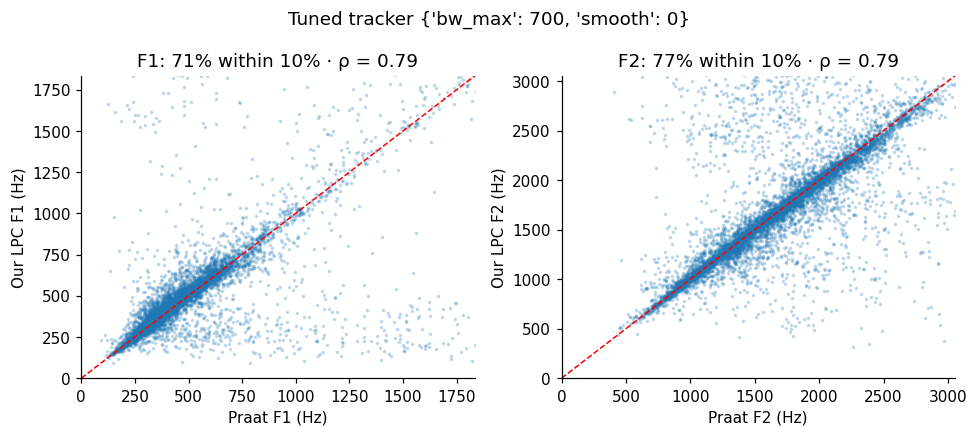

In [ ]:
import parselmouth
from scipy.stats import spearmanr
l2 = load_from_disk(f"{LOCAL}/l2arctic")["scripted"].cast_column("audio", Audio(sampling_rate=SR))
rng = np.random.default_rng(0)
pick = [int(i) for i in rng.choice(len(l2), 40, replace=False)]
clips = [np.asarray(a["array"], dtype=np.float64) for a in l2.select(pick)["audio"]]

ref = []                                     # Praat tracks + voicing, computed once
for x in tqdm(clips, desc="Praat reference"):
    tt, f0, v = pc.pitch_track(x, SR)
    med = np.nanmedian(f0) if np.any(v) else np.nan
    ref.append((x, tt, v, med, parselmouth.Sound(x, SR).to_formant_burg(
        time_step=0.01, max_number_of_formants=5, maximum_formant=pc.formant_ceiling(med))))

configs = [dict(bw_max=400, smooth=0), dict(bw_max=700, smooth=0), dict(bw_max=700, smooth=5),
           dict(bw_max=1000, smooth=5)]
rows, keep = [], {}
for cfg in configs:
    ours, praat = [], []
    for x, tt, v, med, fm in ref:
        t, F, _ = pc.track_formants(x, SR, med, **cfg)
        m = np.interp(t, tt, v.astype(float)) > 0.5
        ours.append(F[m][:, :2])
        praat.append(np.array([[fm.get_value_at_time(k, tk) for k in (1, 2)] for tk in t[m]]).reshape(-1, 2))
    o, p = np.vstack(ours), np.vstack(praat)
    ok = np.all(np.isfinite(o) & np.isfinite(p), axis=1); o, p = o[ok], p[ok]
    keep[str(cfg)] = (o, p)
    for k in range(2):
        d = np.abs(o[:, k] - p[:, k])
        rows.append({"config": str(cfg), "formant": f"F{k+1}", "frames": len(d),
                     "median_abs_diff_Hz": np.median(d), "within_10%": np.mean(d / p[:, k] < 0.1),
                     "pearson_r": np.corrcoef(o[:, k], p[:, k])[0, 1], "spearman_r": spearmanr(o[:, k], p[:, k])[0]})
ftab = pd.DataFrame(rows); ftab.to_csv(f"{RES}/F1_formant_tuning.csv", index=False)
display(ftab.round(3))

best_cfg = ftab.groupby("config")["within_10%"].mean().idxmax()
FORMANT_KW = dict(eval(best_cfg))
json.dump(FORMANT_KW, open(f"{APP_DIR}/formant_config.json", "w"))
print("Chosen formant settings:", FORMANT_KW)

o, p = keep[best_cfg]
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for k, ax in enumerate(axes):
    ax.scatter(p[:, k], o[:, k], s=2, alpha=0.2)
    lim = [0, np.percentile(p[:, k], 99.5)]; ax.plot(lim, lim, "r--", lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel(f"Praat F{k+1} (Hz)"); ax.set_ylabel(f"Our LPC F{k+1} (Hz)")
    r = ftab[(ftab.config == best_cfg) & (ftab.formant == f"F{k+1}")].iloc[0]
    ax.set_title(f"F{k+1}: {r['within_10%']:.0%} within 10% · ρ = {r.spearman_r:.2f}")
plt.suptitle(f"Tuned tracker {FORMANT_KW}"); plt.tight_layout()
plt.savefig(f"{FIG}/F1_lpc_vs_praat_tuned.png", dpi=200); plt.show()

## 2. Indian-English reference norms (IndicTTS)
IndicTTS has studio recordings of English read by fluent native speakers of 13 Indian languages. We stream a sample from each of the 28 data files (no full download) and measure, for every phone:
- **vowel targets:** mean and SD of Lobanov-normalised F1/F2, which give the grey ellipses in the app's vowel chart
- **typical duration** of each phone
- **GOP thresholds:** the 10th percentile of GOP evidence among fluent Indian speakers. A learner's phone is only flagged if it is worse than what 90% of fluent Indian speakers produce.

In [ ]:
from datasets import load_dataset
N_PER_SHARD, N_SHARDS = 60, 28

def stream_indictts(n_per_shard=N_PER_SHARD, n_shards=N_SHARDS):
    items = []
    for i in tqdm(range(n_shards), desc="IndicTTS shards"):
        ds = load_dataset("SPRINGLab/IndicTTS-English", split="train", streaming=True,
                          data_files={"train": f"data/train-{i:05d}-of-{n_shards:05d}.parquet"})
        ds = ds.cast_column("audio", Audio(sampling_rate=SR))
        for ex in ds.take(n_per_shard):
            w = np.asarray(ex["audio"]["array"], dtype=np.float32)
            if 1.0 < len(w) / SR < 15:
                items.append((w, ex["text"], i))
    return items

indic = stream_indictts()
canons = [pc.text_to_phones(t) for _, t, _ in tqdm(indic, desc="g2p")]
ind = features_for([w for w, _, _ in indic], canons, formant_kw=FORMANT_KW, desc="IndicTTS",
                   meta=[{"shard": s} for *_, s in indic])
ind["evidence"] = ind.apply(pa.evidence, axis=1)
ind.to_parquet(f"{RES}/N0_indictts_phone_features.parquet")
print(f"{len(indic)} clips · {len(ind)} phones · {ind.utt.nunique()} utterances analysed")

IndicTTS shards:   0%|          | 0/28 [00:00<?, ?it/s]

README.md:   0%|          | 0.00/325 [00:00<?, ?B/s]

g2p:   0%|          | 0/1635 [00:00<?, ?it/s]

IndicTTS:   0%|          | 0/1635 [00:00<?, ?it/s]

/content/drive/MyDrive/phonolens_data/phonolens_core.py:508: RuntimeWarning: All-NaN slice encountered
  return np.nanmedian(F[m], axis=0)


1635 clips · 63023 phones · 1635 utterances analysed


,zF1,zF2,zF1_sd,zF2_sd,F1_median,F2_median,n
i,-0.61,1.11,0.80,0.80,325.76,2260.09,2056.0
ɪ,-0.68,0.58,0.60,0.87,333.18,1991.23,3521.0
ɛ,0.18,0.47,0.75,0.64,476.36,1904.66,1784.0
æ,0.89,0.07,0.90,0.63,632.82,1730.31,1709.0
ʌ,0.10,-0.19,1.01,0.85,451.69,1604.57,6059.0
ɝ,0.22,-0.22,0.91,0.63,476.70,1567.73,1541.0
ɑ,0.86,-0.90,0.87,0.59,599.11,1249.53,1328.0
u,-0.59,-0.90,0.76,0.88,334.27,1155.82,1207.0
ʊ,-0.50,-1.08,0.57,0.51,372.61,1193.05,297.0
ɔ,0.59,-1.25,0.74,0.57,556.71,1055.23,936.0


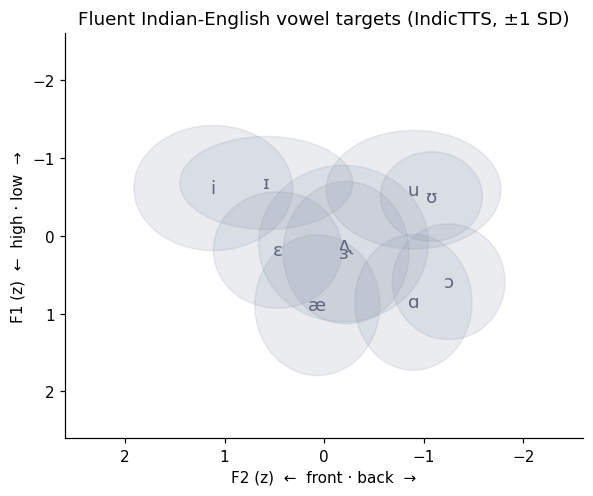

In [ ]:
vow = ind[ind.phone.isin(pc.MONOPHTHONGS) & ind.zF1.notna()]
norms = {"vowels": {}, "durations": {}}
for v, g in vow.groupby("phone"):
    if len(g) >= 30:
        norms["vowels"][v] = {"zF1": g.zF1.mean(), "zF2": g.zF2.mean(), "zF1_sd": g.zF1.std(), "zF2_sd": g.zF2.std(),
                              "F1_median": g.F1.median(), "F2_median": g.F2.median(), "n": int(len(g))}
for p, g in ind.dropna(subset=["dur"]).groupby("phone"):
    norms["durations"][p] = float(g.dur.median())

def make_thresholds(df, pct):
    thr = {"_global": float(np.nanpercentile(df.evidence, pct))}
    for p, g in df.groupby("phone"):
        if g.evidence.notna().sum() >= 30:
            thr[p] = float(np.nanpercentile(g.evidence, pct))
    return thr
THRESH_PCT = 10
thresholds = make_thresholds(ind, THRESH_PCT)
json.dump(norms, open(f"{APP_DIR}/norms.json", "w"), ensure_ascii=False, indent=1)
json.dump(thresholds, open(f"{APP_DIR}/thresholds.json", "w"), ensure_ascii=False, indent=1)

nv = pd.DataFrame(norms["vowels"]).T.sort_values("zF2", ascending=False)
display(nv.round(2))
fig = pa.vowel_chart({"vowels": []}, norms); fig.axes[0].set_title("Fluent Indian-English vowel targets (IndicTTS, ±1 SD)")
fig.savefig(f"{FIG}/N1_indian_vowel_norms.png", dpi=200); display(fig)

## 3. GOP features and a phone scorer trained on expert scores (speechocean762)
Each canonical phone gets:
- **Model features:** CTC likelihood-ratio GOP (substitution and deletion), the phone's peak and mean posterior, the strongest competitor's posterior, duration, whether greedy recognition matched, and phone identity
- **Classical features** (vowels): Lobanov F1/F2, distance from the Indian-English vowel target, and duration relative to the Indian norm

A gradient-boosted regressor predicts the experts' 0–2 phone accuracy score. **Ablation:** does adding the classical features help? The model is chosen with speaker-grouped cross-validation on *train*; *test* is only used for the final numbers.

In [ ]:
so = load_from_disk(f"{LOCAL}/speechocean")
so_frames = []
for split in ["train", "test"]:
    d = so[split].cast_column("audio", Audio(sampling_rate=SR))
    m = d.remove_columns("audio").to_pandas()
    canons, labels, keep = [], [], []
    for i, words in enumerate(m.words):
        ph = pc.arpabet_to_phones([p for w in words for p in w["phones"]])
        acc = [float(a) for w in words for a in w["phones-accuracy"]]
        if ph and len(ph) == len(acc):
            canons.append(ph); labels.append(acc); keep.append(i)
    wavs = [np.asarray(a["array"], dtype=np.float32) for a in d.select(keep)["audio"]]
    meta = [{"speaker": m.speaker[i], "age": int(m.age[i]), "split": split} for i in keep]
    df = features_for(wavs, canons, norms=norms, formant_kw=FORMANT_KW, desc=f"speechocean {split}", meta=meta)
    lab = {(u, k): a for u, acc in enumerate(labels) for k, a in enumerate(acc)}
    df["human"] = [lab[(u, k)] for u, k in zip(df.utt, df.pos)]
    so_frames.append(df)
sofe = pd.concat(so_frames, ignore_index=True)
sofe.to_parquet(f"{RES}/G0_speechocean_phone_features.parquet")
print(sofe.groupby("split").size().rename("phones"))
print("human score distribution:", sofe.human.round().value_counts().sort_index().to_dict())

speechocean train:   0%|          | 0/2500 [00:00<?, ?it/s]

speechocean test:   0%|          | 0/2500 [00:00<?, ?it/s]

split
test     47369
train    47076
Name: phones, dtype: int64
human score distribution: {0.0: 3403, 1.0: 3827, 2.0: 87215}


,features,cv_pcc_train,test_pcc,test_pcc_vowels,test_mse,test_auc_incorrect
0,GOP only (linear),0.608,0.543,0.531,0.098,0.922
1,model features,0.714,0.677,0.668,0.074,0.948
2,model + classical,0.716,0.678,0.669,0.074,0.948


Saved scorer: 'model + classical' (chosen by train CV) · test PCC 0.678


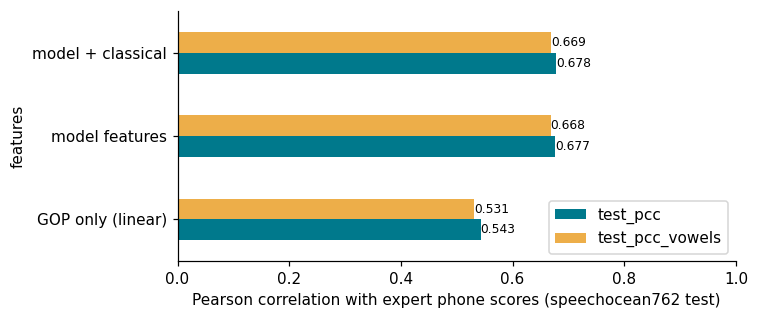

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
import joblib

tr, te = sofe[sofe.split == "train"].copy(), sofe[sofe.split == "test"].copy()
FEATS = {
    "GOP only (linear)": ["gop_sub"],
    "model features": pa.FEATURES_GOP,
    "model + classical": pa.FEATURES_GOP + pa.FEATURES_CLASSICAL,
}
def fit(name, cols, df):
    """Fit one scorer; silently drops feature columns that are empty or constant in `df`."""
    cols = [c for c in cols if df[c].notna().sum() > 1 and df[c].nunique() > 1]
    x = df[cols].astype(float)
    if name.endswith("(linear)"):
        return LinearRegression().fit(x.fillna(MED[cols]), df.human), cols
    cat = [cols.index("phone_id")] if "phone_id" in cols else None
    m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=31,
                                      categorical_features=cat, random_state=0)
    return m.fit(x, df.human), cols                                  # trees handle NaN natively

def predict(name, m, cols, df):
    x = df[cols].astype(float)
    return np.clip(m.predict(x.fillna(MED[cols]) if name.endswith("(linear)") else x), 0, 2)

MED = tr[pa.FEATURES_GOP + pa.FEATURES_CLASSICAL].astype(float).median()
rows = []
for name, cols in FEATS.items():
    cv = []
    for a, b in GroupKFold(n_splits=3).split(tr, groups=tr.speaker):
        m, c = fit(name, cols, tr.iloc[a])
        cv.append(np.corrcoef(predict(name, m, c, tr.iloc[b]), tr.human.iloc[b])[0, 1])
    m, c = fit(name, cols, tr)
    pred = predict(name, m, c, te)
    vmask = (te.is_vowel == 1).values
    rows.append({"features": name, "cv_pcc_train": np.mean(cv), "test_pcc": np.corrcoef(pred, te.human)[0, 1],
                 "test_pcc_vowels": np.corrcoef(pred[vmask], te.human[vmask])[0, 1],
                 "test_mse": np.mean((pred - te.human) ** 2),
                 "test_auc_incorrect": roc_auc_score(te.human < 1.0, -pred) if (te.human < 1.0).any() else np.nan,
                 "_model": m, "_cols": c})
abl = pd.DataFrame(rows)
display(abl.drop(columns=["_model", "_cols"]).round(3))
abl.drop(columns=["_model", "_cols"]).to_csv(f"{RES}/G1_scorer_ablation.csv", index=False)

best = abl.iloc[abl[~abl.features.str.contains("linear")].cv_pcc_train.idxmax()]
joblib.dump({"model": best._model, "features": best._cols, "name": best.features}, f"{APP_DIR}/scorer.joblib")
print(f"Saved scorer: '{best.features}' (chosen by train CV) · test PCC {best.test_pcc:.3f}")

fig, ax = plt.subplots(figsize=(7, 3))
d = abl.set_index("features")[["test_pcc", "test_pcc_vowels"]]
d.plot.barh(ax=ax, color=["#00798c", "#edae49"])
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
ax.set_xlabel("Pearson correlation with expert phone scores (speechocean762 test)"); ax.set_xlim(0, 1)
plt.tight_layout(); plt.savefig(f"{FIG}/G1_scorer_ablation.png", dpi=200); plt.show()

## 4. Rule A (strict) vs Rule B (Indian-English-aware) on the unseen Hindi-L1 speakers
- **Rule A:** flag whenever the recognised phone differs from the dictionary phone.
- **Rule B:** flag only if the difference is *not* a standard Indian-English realisation **and** the GOP evidence is worse than what 90% of fluent Indian speakers produce for that phone.

The threshold sweep shows the precision/recall trade-off as the percentile changes.

Hindi test:   0%|          | 0/600 [00:00<?, ?it/s]

,labels,rule,precision,recall,f1,false_rejection_rate,diagnosis_acc,flag_rate
0,strict labels,A: strict,0.527,0.501,0.514,0.072,0.763,0.131
1,strict labels,B: Indian-aware (p10),0.506,0.164,0.247,0.025,0.662,0.044
2,Indian-aware labels,A: strict,0.466,0.519,0.491,0.079,0.773,0.131
3,Indian-aware labels,B: Indian-aware (p10),0.487,0.185,0.268,0.026,0.689,0.044


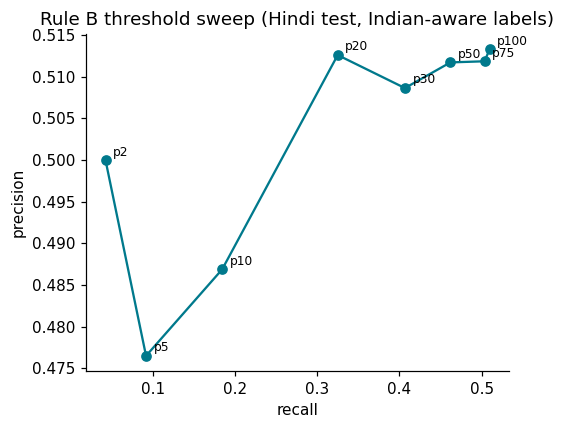

In [ ]:
meta_l2 = l2.remove_columns("audio").to_pandas()
splits = json.load(open(f"{RES}/splits.json"))
test_idx = meta_l2.index[meta_l2.speaker_code.isin(splits["test_hindi"])].tolist()
test_can = [pc.ipa_to_phones(s) for s in meta_l2.loc[test_idx, "g2p"]]
test_ann = [pc.ipa_to_phones(s) for s in meta_l2.loc[test_idx, "ipa"]]
test_wavs = [np.asarray(a["array"], dtype=np.float32) for a in l2.select(test_idx)["audio"]]
hin = features_for(test_wavs, test_can, norms=norms, formant_kw=FORMANT_KW, desc="Hindi test",
                   meta=[{"speaker": s} for s in meta_l2.loc[test_idx, "speaker_code"]])
ann_real = {u: pc.realised_per_canonical(c, a) for u, (c, a) in enumerate(zip(test_can, test_ann))}
hin["annotated"] = [ann_real[u][k] for u, k in zip(hin.utt, hin.pos)]

def mdd_from_flags(df, flags, accept):
    truth = np.array([not pc._same(c, a, accept) for c, a in zip(df.phone, df.annotated)])
    flags = np.asarray(flags, dtype=bool)
    TR, FR, FA = (truth & flags).sum(), (~truth & flags).sum(), (truth & ~flags).sum()
    p, r = TR / max(1, TR + FR), TR / max(1, TR + FA)
    diag = (truth & flags & (df.heard.values == df.annotated.values)).sum() / max(1, TR)
    return {"precision": p, "recall": r, "f1": 2 * p * r / max(1e-9, p + r),
            "false_rejection_rate": FR / max(1, (~truth).sum()), "diagnosis_acc": diag,
            "flag_rate": flags.mean()}

rows = []
fa = [pa.flag_strict(r) for r in hin.to_dict("records")]
fb = [pa.flag_indian(r, thresholds) for r in hin.to_dict("records")]
for mode, acc in [("strict labels", frozenset()), ("Indian-aware labels", pc.INDIAN_ENGLISH_ACCEPT)]:
    rows.append({"labels": mode, "rule": "A: strict", **mdd_from_flags(hin, fa, acc)})
    rows.append({"labels": mode, "rule": f"B: Indian-aware (p{THRESH_PCT})", **mdd_from_flags(hin, fb, acc)})
rules = pd.DataFrame(rows); rules.to_csv(f"{RES}/R1_rule_A_vs_B_hindi.csv", index=False)
display(rules.round(3))

sweep = []
for pct in [2, 5, 10, 20, 30, 50, 75, 100]:
    thr = make_thresholds(ind, pct) if pct < 100 else {"_global": np.inf}
    f = [pa.flag_indian(r, thr) for r in hin.to_dict("records")]
    sweep.append({"percentile": pct, **mdd_from_flags(hin, f, pc.INDIAN_ENGLISH_ACCEPT)})
sweep = pd.DataFrame(sweep); sweep.to_csv(f"{RES}/R2_threshold_sweep.csv", index=False)
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(sweep.recall, sweep.precision, "o-", color="#00798c")
for _, r in sweep.iterrows():
    ax.annotate(f"p{int(r.percentile)}", (r.recall, r.precision), textcoords="offset points", xytext=(5, 3), fontsize=8)
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Rule B threshold sweep (Hindi test, Indian-aware labels)")
plt.tight_layout(); plt.savefig(f"{FIG}/R2_threshold_sweep.png", dpi=200); plt.show()

## 5. Accent-fairness check on Svarah (19 Indian first languages)
Svarah speakers are reading or speaking normally, and we have no error labels, so we compare **how often each rule flags phones** for speakers of each first language. A fair system should not flag one language group far more than another just because of accent.

g2p:   0%|          | 0/760 [00:00<?, ?it/s]

Svarah:   0%|          | 0/760 [00:00<?, ?it/s]

,mean flag rate,max / min ratio,coefficient of variation
rule_A,0.228,1.678,0.148
rule_B,0.144,2.299,0.213


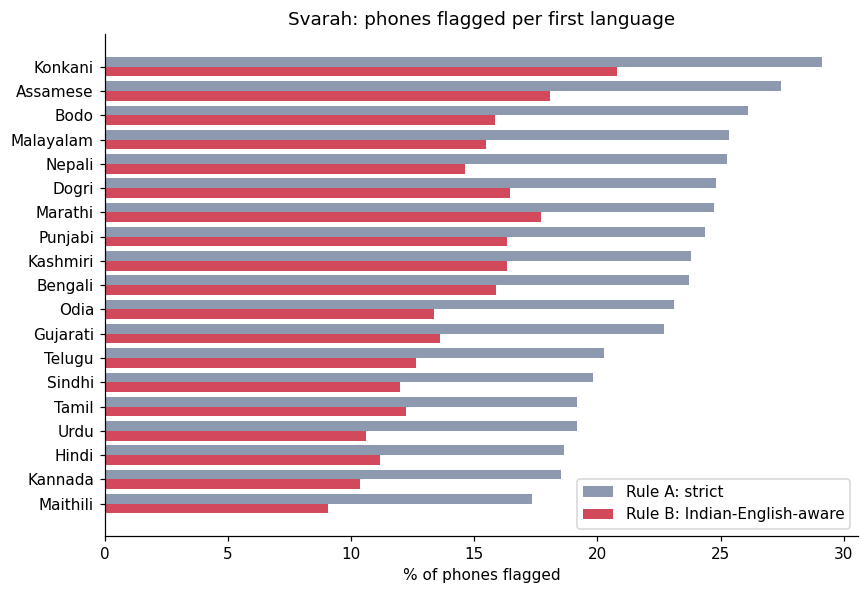

In [ ]:
N_PER_LANG = 40
sv = load_from_disk(f"{LOCAL}/svarah")
svm = sv.remove_columns("audio_filepath").to_pandas()
pick = svm[svm.duration.between(2, 15)].sample(frac=1, random_state=0) \
          .groupby("primary_language").head(N_PER_LANG).index.tolist()
sv_wavs = [np.asarray(a["array"], dtype=np.float32) for a in sv.select(pick)["audio_filepath"]]
sv_can = [pc.text_to_phones(t) for t in tqdm(svm.loc[pick, "text"], desc="g2p")]
svf = features_for(sv_wavs, sv_can, norms=norms, formant_kw=FORMANT_KW, desc="Svarah",
                   meta=[{"language": svm.loc[i, "primary_language"], "state": svm.loc[i, "native_place_state"]} for i in pick])
svf["rule_A"] = [pa.flag_strict(r) for r in svf.to_dict("records")]
svf["rule_B"] = [pa.flag_indian(r, thresholds) for r in svf.to_dict("records")]
fair = svf.groupby("language")[["rule_A", "rule_B"]].mean().sort_values("rule_A")
fair["clips"] = svf.groupby("language").utt.nunique()
fair.to_csv(f"{RES}/S1_svarah_flag_rates.csv")

summary = pd.DataFrame({r: {"mean flag rate": fair[r].mean(), "max / min ratio": fair[r].max() / max(1e-9, fair[r].min()),
                            "coefficient of variation": fair[r].std() / fair[r].mean()} for r in ["rule_A", "rule_B"]}).T
display(summary.round(3))

fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(fair))
ax.barh(y + 0.2, fair.rule_A * 100, height=0.4, color="#8d99ae", label="Rule A: strict")
ax.barh(y - 0.2, fair.rule_B * 100, height=0.4, color="#d1495b", label="Rule B: Indian-English-aware")
ax.set_yticks(y); ax.set_yticklabels(fair.index); ax.set_xlabel("% of phones flagged")
ax.set_title("Svarah: phones flagged per first language"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/S1_svarah_fairness.png", dpi=200); plt.show()

## 6. Final engine check

In [ ]:
importlib.reload(pa)
engine = pa.Engine(FT_BEST, APP_DIR, device=DEVICE)
print({k: v for k, v in [("scorer", engine.scorer is not None and engine.scorer["name"]),
                          ("norms", engine.norms is not None), ("formant", engine.formant_kw)]})
i = pick[0]
res = engine.analyze(sv_wavs[0], svm.loc[i, "text"])
print(f"[{svm.loc[i, 'primary_language']}] {svm.loc[i, 'text']}")
print("overall:", res.get("overall"), "| flagged:", [(p["expected"], p["heard"]) for p in res.get("phones", []) if not p["ok"]])
from IPython.display import HTML
display(HTML(pa.render_html(res)))

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

{'scorer': 'model + classical', 'norms': True, 'formant': {'bw_max': 700, 'smooth': 0}}
[Maithili] I have read English from 6th standard onwards and continued till my graduation
overall: 92.9 | flagged: [('ɡ', '-'), ('t', 'ɪ'), ('i', 'k'), ('eɪ', 's'), ('tʃ', 'θ'), ('dʒ', 'd')]


## 7. Gradio app
Opens inline and prints a public `*.gradio.live` link (valid for about 72 h while this runtime is alive). Record with the microphone or upload a file.

In [ ]:
demo = pa.build_gradio(engine)
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://27c3fd346b9bca7d7a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 8. FastAPI backup (+ Cloudflare tunnel)
Starts the REST API inside Colab and exposes it at a public `https://….trycloudflare.com` URL (no account needed). A React app can call `POST /analyze` with form fields `audio` (any format, including browser WebM) and `text`.

In [ ]:
import threading, uvicorn, requests, subprocess, re, io, soundfile as sf
api = pa.build_api(engine)
server = uvicorn.Server(uvicorn.Config(api, host="0.0.0.0", port=8000, log_level="warning"))
threading.Thread(target=server.run, daemon=True).start()
for _ in range(60):
    try:
        if requests.get("http://localhost:8000/health", timeout=1).ok: break
    except Exception:
        time.sleep(0.5)
print("local health:", requests.get("http://localhost:8000/health").json())

buf = io.BytesIO(); sf.write(buf, sv_wavs[0], SR, format="WAV")
r = requests.post("http://localhost:8000/analyze", files={"audio": ("test.wav", buf.getvalue(), "audio/wav")},
                  data={"text": svm.loc[pick[0], "text"]})
print("local /analyze:", r.status_code, "overall =", r.json().get("overall"))

local health: {'status': 'ok', 'device': 'cuda', 'scorer': True, 'norms': True}
local /analyze: 200 overall = 92.9


In [ ]:
if not os.path.exists("/content/cloudflared"):
    subprocess.run(["wget", "-q", "https://github.com/cloudflare/cloudflared/releases/latest/download/"
                    "cloudflared-linux-amd64", "-O", "/content/cloudflared"], check=True)
    os.chmod("/content/cloudflared", 0o755)
tunnel = subprocess.Popen(["/content/cloudflared", "tunnel", "--url", "http://localhost:8000", "--no-autoupdate"],
                          stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
PUBLIC_URL, t0 = None, time.time()
while time.time() - t0 < 60 and PUBLIC_URL is None:
    line = tunnel.stdout.readline()
    m = re.search(r"https://[-a-z0-9]+\.trycloudflare\.com", line)
    if m: PUBLIC_URL = m.group(0)
threading.Thread(target=lambda: [None for _ in tunnel.stdout], daemon=True).start()   # keep draining logs
print("PUBLIC API URL:", PUBLIC_URL)
print(f'''
Try it from anywhere:
  curl {PUBLIC_URL}/health
  curl -X POST {PUBLIC_URL}/analyze -F "audio=@recording.webm" -F "text=The thin vest was very warm."
Interactive docs: {PUBLIC_URL}/docs
(The URL changes every time this cell runs; for React, put it in .env as VITE_API_URL.)''')

PUBLIC API URL: https://ide-concentrations-significant-therefore.trycloudflare.com

Try it from anywhere:
  curl https://ide-concentrations-significant-therefore.trycloudflare.com/health
  curl -X POST https://ide-concentrations-significant-therefore.trycloudflare.com/analyze -F "audio=@recording.webm" -F "text=The thin vest was very warm."
Interactive docs: https://ide-concentrations-significant-therefore.trycloudflare.com/docs
(The URL changes every time this cell runs; for React, put it in .env as VITE_API_URL.)


## 9. Package for running on a laptop (no Colab needed)
Writes `MyDrive/phonolens_data/server/` with `server.py`, both modules, `requirements.txt` and a README, and copies the fine-tuned model and app assets into it. Download that one folder.

In [ ]:
import sklearn, transformers
SRV = f"{SAVE}/server"
os.makedirs(SRV, exist_ok=True)
shutil.copy(f"{SAVE}/phonolens_core.py", SRV); shutil.copy(f"{SAVE}/phonolens_app.py", SRV)
for src, dst in [(FT_BEST, f"{SRV}/phonolens-ft"), (APP_DIR, f"{SRV}/phonolens-app")]:
    if os.path.exists(dst): shutil.rmtree(dst)
    shutil.copytree(src, dst, ignore=shutil.ignore_patterns("train_state.json"))

open(f"{SRV}/server.py", "w").write('''"""PhonoLens backend: FastAPI (+ optional Gradio UI at /ui).

    python server.py            # API on http://localhost:8000  (docs at /docs)
    python server.py --ui       # API + Gradio UI at http://localhost:8000/ui
"""
import argparse, os, sys
HERE = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, HERE)
from phonolens_app import Engine, build_api, build_gradio

MODEL_DIR = os.environ.get("PHONOLENS_MODEL", os.path.join(HERE, "phonolens-ft"))
ASSETS_DIR = os.environ.get("PHONOLENS_ASSETS", os.path.join(HERE, "phonolens-app"))
engine = Engine(MODEL_DIR, ASSETS_DIR)
app = build_api(engine)

if __name__ == "__main__":
    import uvicorn
    ap = argparse.ArgumentParser()
    ap.add_argument("--ui", action="store_true", help="also serve the Gradio UI at /ui")
    ap.add_argument("--port", type=int, default=8000)
    args = ap.parse_args()
    if args.ui:
        import gradio as gr
        app = gr.mount_gradio_app(app, build_gradio(engine), path="/ui")
    print(f"PhonoLens running on http://localhost:{args.port}  (device: {engine.device})")
    uvicorn.run(app, host="0.0.0.0", port=args.port)
''')

open(f"{SRV}/requirements.txt", "w").write(f'''torch
transformers>={transformers.__version__.split(".")[0]}.0
scikit-learn=={sklearn.__version__}
numpy
scipy
pandas
librosa
soundfile
joblib
matplotlib
g2p_en
nltk
fastapi
uvicorn
python-multipart
gradio
''')

open(f"{SRV}/README.md", "w").write('''# PhonoLens server
1. Install Python 3.10+ and **ffmpeg** (needed for browser WebM audio):
   - Windows: `winget install ffmpeg`   - macOS: `brew install ffmpeg`
2. `pip install -r requirements.txt`  (scikit-learn is pinned so the saved scorer loads)
3. `python server.py --ui` then open http://localhost:8000/ui (app) or http://localhost:8000/docs (API)

API: `POST /analyze` (multipart: `audio` file, `text` string) → JSON with overall score, per-word and
per-phone results (`expected`, `heard`, `ok`, `score`, `start`, `end`, `tip`), vowel formants and tips.
`GET /prompts`, `GET /health`. CORS is open, so a React dev server can call it directly.
''')
!du -sh {SRV}; ls {SRV}

1.2G	/content/drive/MyDrive/phonolens_data/server
phonolens-app	  phonolens_core.py  README.md	       server.py
phonolens_app.py  phonolens-ft	     requirements.txt


## Summary

In [ ]:
print("Formant tracker:", FORMANT_KW)
print("\nScorer ablation (speechocean762 test):"); display(abl.drop(columns=["_model", "_cols"]).round(3))
print("\nRule A vs B on unseen Hindi-L1 speakers:"); display(rules.round(3))
print("\nSvarah fairness:"); display(summary.round(3))

Formant tracker: {'bw_max': 700, 'smooth': 0}

Scorer ablation (speechocean762 test):


,features,cv_pcc_train,test_pcc,test_pcc_vowels,test_mse,test_auc_incorrect
0,GOP only (linear),0.608,0.543,0.531,0.098,0.922
1,model features,0.714,0.677,0.668,0.074,0.948
2,model + classical,0.716,0.678,0.669,0.074,0.948



Rule A vs B on unseen Hindi-L1 speakers:


,labels,rule,precision,recall,f1,false_rejection_rate,diagnosis_acc,flag_rate
0,strict labels,A: strict,0.527,0.501,0.514,0.072,0.763,0.131
1,strict labels,B: Indian-aware (p10),0.506,0.164,0.247,0.025,0.662,0.044
2,Indian-aware labels,A: strict,0.466,0.519,0.491,0.079,0.773,0.131
3,Indian-aware labels,B: Indian-aware (p10),0.487,0.185,0.268,0.026,0.689,0.044



Svarah fairness:


,mean flag rate,max / min ratio,coefficient of variation
rule_A,0.228,1.678,0.148
rule_B,0.144,2.299,0.213


In [ ]:
import json, numpy as np, pandas as pd, os
SAVE = "/content/drive/MyDrive/phonolens_data"
if not os.path.exists(SAVE):
    from google.colab import drive; drive.mount('/content/drive')
ind = pd.read_parquet(f"{SAVE}/results/N0_indictts_phone_features.parquet")
PCT = 50
thr = {"_global": float(np.nanpercentile(ind.evidence, PCT))}
for p, g in ind.groupby("phone"):
    if g.evidence.notna().sum() >= 30:
        thr[p] = float(np.nanpercentile(g.evidence, PCT))
for d in [f"{SAVE}/models/phonolens-app", f"{SAVE}/server/phonolens-app"]:
    json.dump(thr, open(f"{d}/thresholds.json", "w"), ensure_ascii=False, indent=1)
if "engine" in globals():
    engine.thresholds = thr          # updates the running Gradio app immediately
print(f"Thresholds set to p{PCT} ✅")

Thresholds set to p50 ✅
